# AV2 — Entrega de 13/11/2026: Seeds

Limpeza e pré-processamento, análise exploratória (EDA) e seleção de atributos para classificar as variedades **Kama (1), Rosa (2) e Canadian (3)**. Execute as células em ordem no Google Colab ou em Jupyter.

O notebook lê `dados/dataset-seeds.txt` (arquivo original) ou `dados/dataset-seeds.csv` (cópia com cabeçalho). No Colab, envie um desses arquivos para `/content/` ou mantenha a pasta `dados/` junto ao notebook. O conjunto de teste será separado antes da EDA e da seleção de atributos e ficará reservado para uma entrega posterior.

## 1. Importação das bibliotecas

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 2. Configuração de exibição

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

## 3. Coleta e leitura dos dados

In [3]:
colunas = [
    "area", "perimetro", "compacidade", "comprimento_grao",
    "largura_grao", "coeficiente_assimetria", "comprimento_sulco", "classe",
]
candidatos = [
    Path("dados/dataset-seeds.txt"),
    Path("dados/dataset-seeds.csv"),
    Path("dataset-seeds.txt"),
    Path("dataset-seeds.csv"),
    Path("/content/dados/dataset-seeds.txt"),
    Path("/content/dados/dataset-seeds.csv"),
    Path("/content/dataset-seeds.txt"),
    Path("/content/dataset-seeds.csv"),
]
caminho_dados = next((p for p in candidatos if p.is_file()), None)
if caminho_dados is None:
    raise FileNotFoundError("Coloque dataset-seeds.txt ou dataset-seeds.csv em dados/ ou /content/.")

if caminho_dados.suffix == ".txt":
    # Original UCI: sem cabeçalho, com espaços e tabulações entre os valores.
    dados = pd.read_csv(caminho_dados, sep=r"\s+", header=None, names=colunas)
else:
    # CSV do projeto: cabeçalho, ponto e vírgula e ponto decimal.
    dados = pd.read_csv(caminho_dados, sep=";")
    if dados.columns.tolist() != colunas:
        raise ValueError("As colunas do CSV não correspondem ao esquema esperado.")
print(f"Arquivo: {caminho_dados} | dimensão inicial: {dados.shape}")

Arquivo: dados\dataset-seeds.txt | dimensão inicial: (210, 8)


In [4]:
display(dados.head())

,area,perimetro,compacidade,comprimento_grao,largura_grao,coeficiente_assimetria,comprimento_sulco,classe
0,15.26,14.84,0.871,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.881,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.905,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.895,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.903,5.658,3.562,1.355,5.175,1


## 4. Limpeza e verificação de consistência

In [5]:
# Conversão explícita: texto inesperado passa a ausente e entra na auditoria.
dados_numericos = dados.apply(pd.to_numeric, errors="coerce")
atributos = colunas[:-1]
auditoria = pd.DataFrame({
    "tipo": dados_numericos.dtypes.astype(str),
    "ausentes": dados_numericos.isna().sum(),
    "valores_unicos": dados_numericos.nunique(dropna=True),
})
print(f"Linhas duplicadas exatas: {dados_numericos.duplicated().sum()}")
print(f"Medidas infinitas: {np.isinf(dados_numericos[atributos].to_numpy()).sum()}")
display(auditoria)

Linhas duplicadas exatas: 0
Medidas infinitas: 0


,tipo,ausentes,valores_unicos
area,float64,0,193
perimetro,float64,0,170
compacidade,float64,0,186
comprimento_grao,float64,0,188
largura_grao,float64,0,184
coeficiente_assimetria,float64,0,207
comprimento_sulco,float64,0,148
classe,int64,0,3


In [6]:
# Primeiro, elimine registros incompletos; depois, duplicatas exatas.
sem_ausentes = dados_numericos.replace([np.inf, -np.inf], np.nan).dropna().copy()
sem_duplicatas = sem_ausentes.drop_duplicates().copy()
valores_validos = (
    sem_duplicatas["classe"].isin([1, 2, 3])
    & sem_duplicatas[atributos].gt(0).all(axis=1)
    & sem_duplicatas["compacidade"].between(0, 1)
)
dados_limpos = sem_duplicatas.loc[valores_validos].copy()
dados_limpos["classe"] = dados_limpos["classe"].astype(int)

resumo_limpeza = pd.Series({
    "linhas_originais": len(dados),
    "removidas_por_ausencia_texto_ou_infinito": len(dados) - len(sem_ausentes),
    "duplicatas_exatas_removidas": len(sem_ausentes) - len(sem_duplicatas),
    "removidas_por_valores_invalidos": (~valores_validos).sum(),
    "linhas_finais": len(dados_limpos),
}, name="quantidade")
display(resumo_limpeza.to_frame())
if dados_limpos.empty:
    raise ValueError("Nenhuma linha válida após a limpeza.")

,quantidade
linhas_originais,210
removidas_por_ausencia_texto_ou_infinito,0
duplicatas_exatas_removidas,0
removidas_por_valores_invalidos,0
linhas_finais,210


A auditoria verifica ausências, texto inesperado, infinitos, duplicatas, classes fora de 1–3, medidas não positivas e compacidade fora de 0–1. O arquivo fornecido não exige remoção nem imputação. Valores extremos plausíveis serão examinados na EDA, sem exclusão automática.

## 5. Pré-processamento e separação do teste

In [7]:
X = dados_limpos[atributos].copy()
y = dados_limpos["classe"].copy()
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {X_treino.shape} | Teste reservado: {X_teste.shape}")
print("Classes no treino:", y_treino.value_counts().sort_index().to_dict())
print("Classes no teste:", y_teste.value_counts().sort_index().to_dict())

Treino: (168, 7) | Teste reservado: (42, 7)
Classes no treino: {1: 56, 2: 56, 3: 56}
Classes no teste: {1: 14, 2: 14, 3: 14}


A EDA abaixo usa apenas o treino, preservando o teste para avaliação futura. A padronização será ajustada dentro do pipeline de validação cruzada, somente com o treino de cada dobra. A seleção de atributos também será refeita em cada dobra.

## 6. Análise exploratória dos dados (EDA)

In [8]:
nomes_classes = {1: "Kama", 2: "Rosa", 3: "Canadian"}
ordem_classes = list(nomes_classes.values())
dados_eda = X_treino.assign(variedade=y_treino.map(nomes_classes))
print("Distribuição das classes no treino:")
display(dados_eda["variedade"].value_counts().reindex(ordem_classes).to_frame("amostras"))
print("Estatísticas descritivas do treino:")
display(X_treino.describe().T)
print("Médias dos atributos por variedade no treino:")
display(dados_eda.groupby("variedade")[atributos].mean().reindex(ordem_classes).T)

Distribuição das classes no treino:


,amostras
variedade,
Kama,56
Rosa,56
Canadian,56


Estatísticas descritivas do treino:


,count,mean,std,min,25%,50%,75%,max
area,168.0,14.888,2.905,10.590,12.378,14.405,17.275,21.180
perimetro,168.0,14.574,1.301,12.410,13.470,14.360,15.738,17.230
compacidade,168.0,0.872,0.024,0.808,0.859,0.875,0.888,0.918
comprimento_grao,168.0,5.631,0.440,4.899,5.266,5.515,5.985,6.675
largura_grao,168.0,3.266,0.376,2.630,2.967,3.258,3.562,4.033
coeficiente_assimetria,168.0,3.687,1.533,0.765,2.457,3.599,4.733,8.456
comprimento_sulco,168.0,5.408,0.493,4.519,5.042,5.220,5.877,6.550


Médias dos atributos por variedade no treino:


variedade,Kama,Rosa,Canadian
area,14.434,18.362,11.869
perimetro,14.343,16.141,13.239
compacidade,0.881,0.884,0.850
comprimento_grao,5.523,6.147,5.223
largura_grao,3.260,3.681,2.857
coeficiente_assimetria,2.583,3.659,4.819
comprimento_sulco,5.100,6.024,5.099


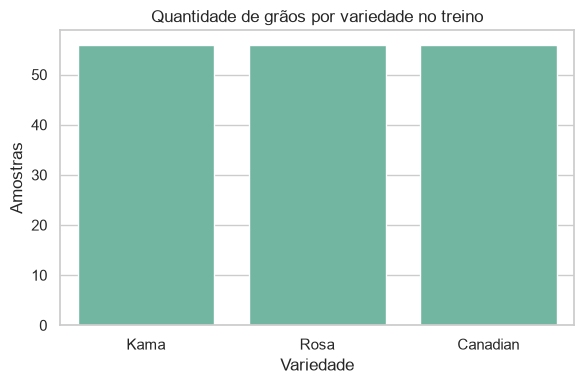

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=dados_eda, x="variedade", order=ordem_classes, ax=ax)
ax.set(title="Quantidade de grãos por variedade no treino", xlabel="Variedade", ylabel="Amostras")
plt.tight_layout()
plt.show()

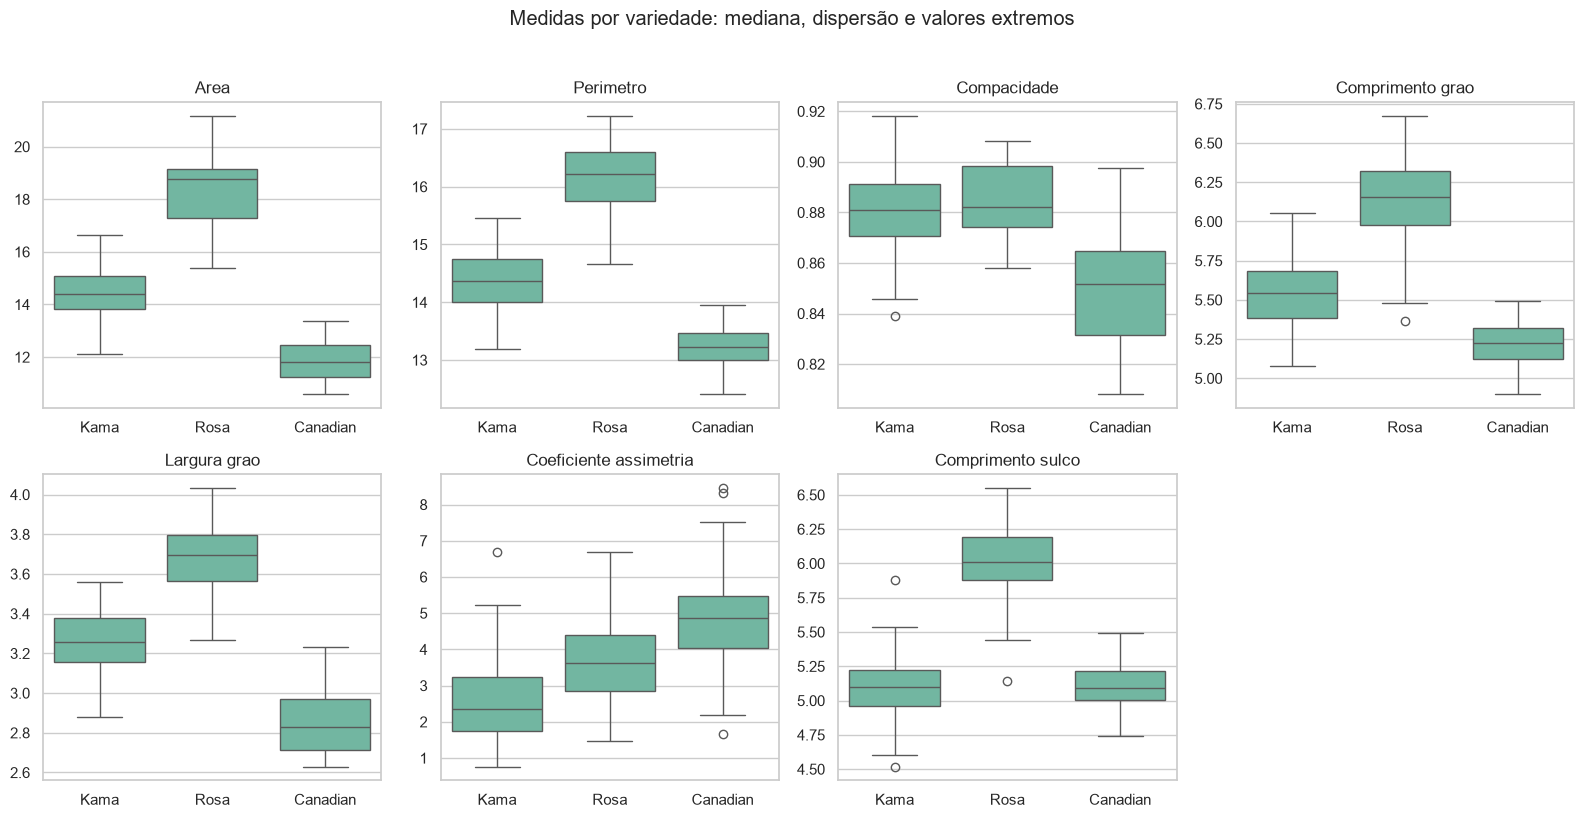

In [10]:
fig, eixos = plt.subplots(2, 4, figsize=(16, 8))
for eixo, atributo in zip(eixos.flat, atributos):
    sns.boxplot(data=dados_eda, x="variedade", y=atributo, order=ordem_classes, ax=eixo)
    eixo.set(xlabel="", ylabel="", title=atributo.replace("_", " ").capitalize())
eixos.flat[-1].axis("off")
fig.suptitle("Medidas por variedade: mediana, dispersão e valores extremos", y=1.02)
plt.tight_layout()
plt.show()

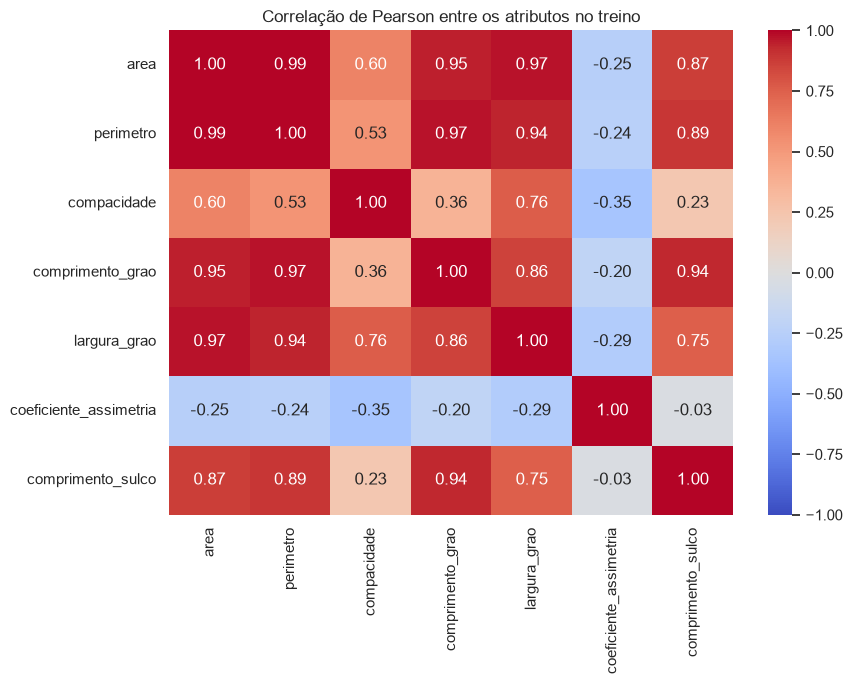

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(X_treino.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson entre os atributos no treino")
plt.tight_layout()
plt.show()

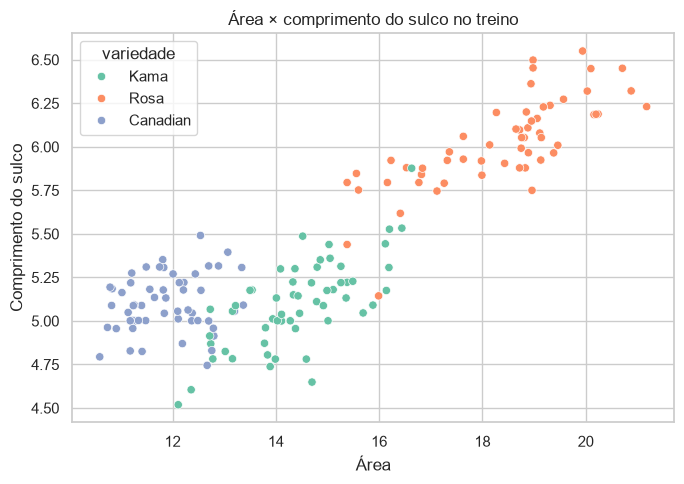

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(
    data=dados_eda, x="area", y="comprimento_sulco", hue="variedade",
    hue_order=ordem_classes, palette="Set2", ax=ax,
)
ax.set(title="Área × comprimento do sulco no treino", xlabel="Área", ylabel="Comprimento do sulco")
plt.tight_layout()
plt.show()

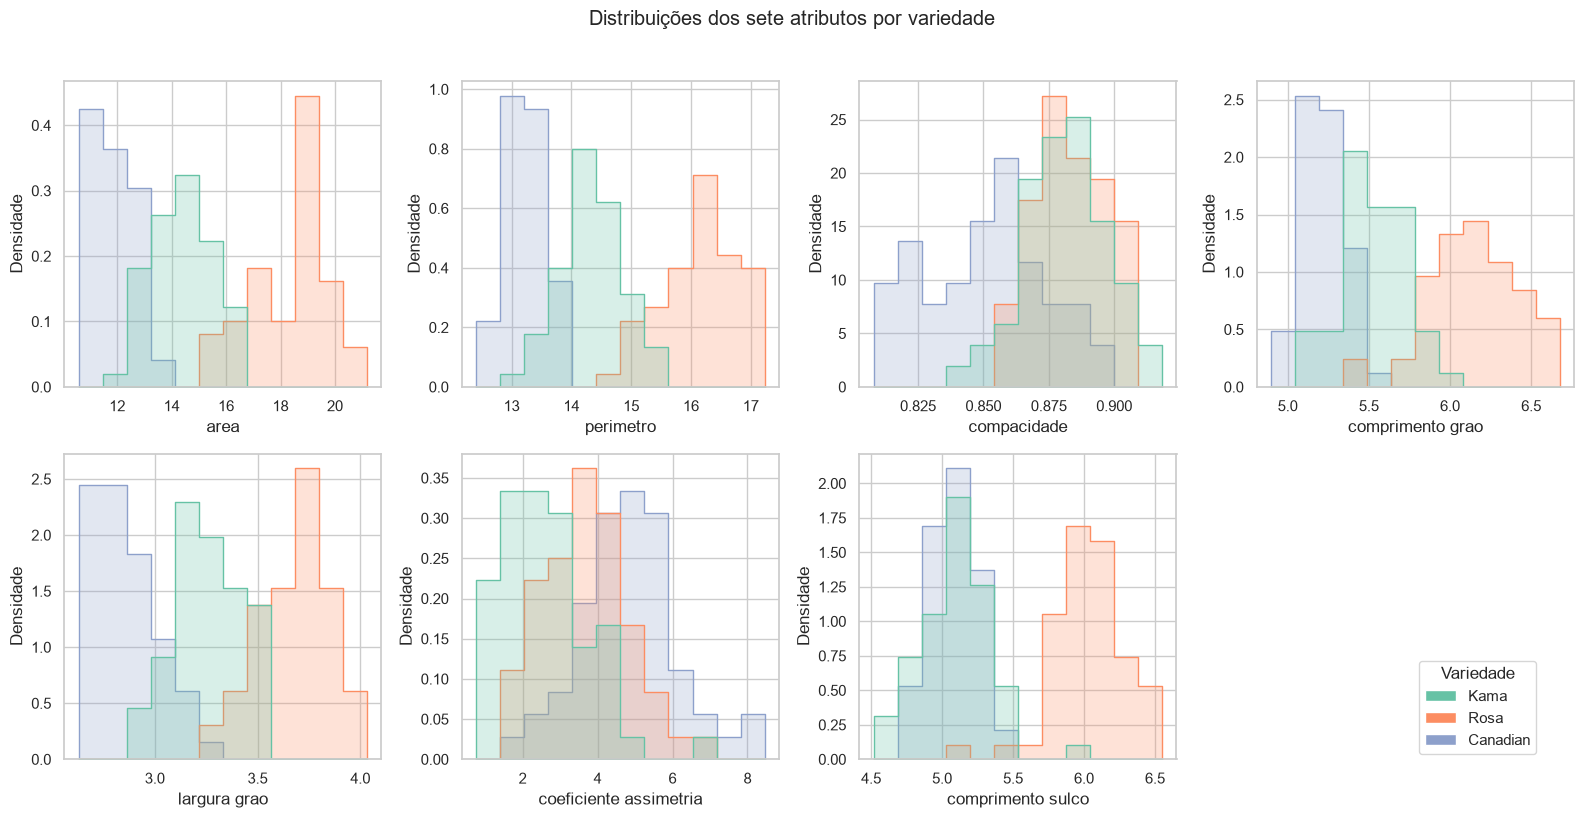

In [13]:
# Distribuições completas ajudam a comparar sobreposição e assimetria das classes.
fig, eixos = plt.subplots(2, 4, figsize=(16, 8))
for eixo, atributo in zip(eixos.flat, atributos):
    sns.histplot(
        data=dados_eda, x=atributo, hue="variedade", hue_order=ordem_classes,
        bins=12, element="step", stat="density", common_norm=False, palette="Set2",
        alpha=0.25, ax=eixo, legend=False,
    )
    eixo.set(xlabel=atributo.replace("_", " "), ylabel="Densidade")
eixos.flat[-1].axis("off")
fig.suptitle("Distribuições dos sete atributos por variedade", y=1.02)
from matplotlib.patches import Patch
cores = sns.color_palette("Set2", len(ordem_classes))
fig.legend(handles=[Patch(facecolor=cor, label=nome) for cor, nome in zip(cores, ordem_classes)],
           title="Variedade", loc="lower right", bbox_to_anchor=(0.97, 0.08))
plt.tight_layout()
plt.show()

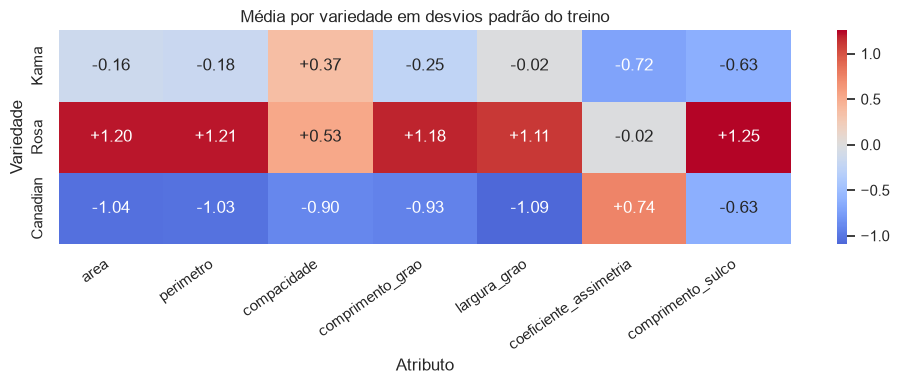

In [14]:
# Médias padronizadas permitem comparar atributos em escalas diferentes.
medias_por_classe = dados_eda.groupby("variedade")[atributos].mean().reindex(ordem_classes)
medias_padronizadas = (medias_por_classe - X_treino.mean()) / X_treino.std(ddof=0)
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(medias_padronizadas, annot=True, fmt="+.2f", cmap="coolwarm", center=0, ax=ax)
ax.set(title="Média por variedade em desvios padrão do treino", xlabel="Atributo", ylabel="Variedade")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Leitura da EDA:** no treino, a variedade Rosa apresenta maiores médias de área, perímetro, comprimento e largura do grão e comprimento do sulco. A Canadian tem as menores médias dessas medidas e o maior coeficiente de assimetria. Kama fica, em geral, entre as duas nas medidas de tamanho. Área e perímetro têm correlação de Pearson de aproximadamente **0,99**, sinal de informação redundante; por isso a utilidade de um atributo deve ser verificada também em conjunto com os demais.

## 7. Seleção de atributos

O teste F da ANOVA ordena os atributos conforme a associação com as classes no **treino**. Para comparar tamanhos de subconjunto, a seleção é refeita dentro de cada dobra da validação cruzada. A regressão logística serve apenas como referência exploratória nesta etapa; a modelagem e avaliação final ficam para as próximas entregas.

In [15]:
seletor_ranking = SelectKBest(score_func=f_classif, k="all")
seletor_ranking.fit(X_treino, y_treino)
ranking = pd.DataFrame({
    "atributo": atributos,
    "estatistica_F": seletor_ranking.scores_,
    "valor_p": seletor_ranking.pvalues_,
}).sort_values("estatistica_F", ascending=False).reset_index(drop=True)
display(ranking)

,atributo,estatistica_F,valor_p
0,area,466.650,1.210e-68
1,perimetro,464.781,1.604e-68
2,largura_grao,347.075,7.616e-60
3,comprimento_sulco,302.303,6.688e-56
4,comprimento_grao,275.493,2.587e-53
5,compacidade,57.793,9.482e-20
6,coeficiente_assimetria,45.732,1.577e-16


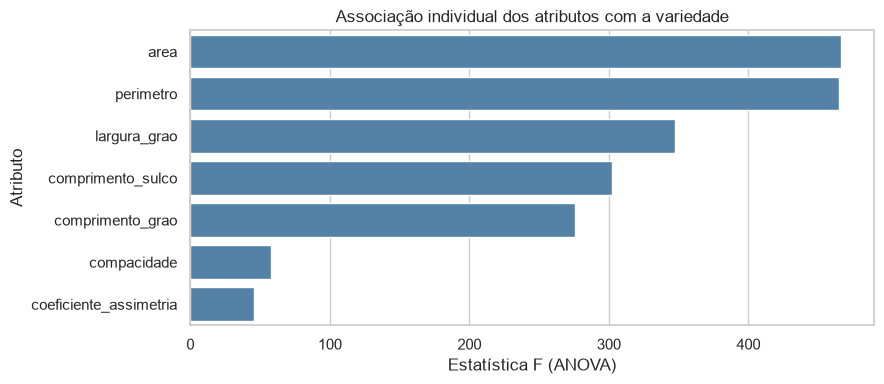

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=ranking, x="estatistica_F", y="atributo", color="steelblue", ax=ax)
ax.set(title="Associação individual dos atributos com a variedade", xlabel="Estatística F (ANOVA)", ylabel="Atributo")
plt.tight_layout()
plt.show()

In [17]:
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultados = []
for k in range(1, len(atributos) + 1):
    pipeline = Pipeline([
        ("selecao", SelectKBest(score_func=f_classif, k=k)),
        ("padronizacao", StandardScaler()),
        ("classificador", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    acuracias = cross_val_score(pipeline, X_treino, y_treino, cv=validacao, scoring="accuracy")
    resultados.append({
        "k": k,
        "acuracia_media": acuracias.mean(),
        "desvio_entre_dobras": acuracias.std(ddof=1),
    })
comparacao = pd.DataFrame(resultados)
display(comparacao.round(3))

,k,acuracia_media,desvio_entre_dobras
0,1,0.875,0.058
1,2,0.869,0.063
2,3,0.869,0.062
3,4,0.929,0.046
4,5,0.946,0.050
5,6,0.946,0.050
6,7,0.929,0.062


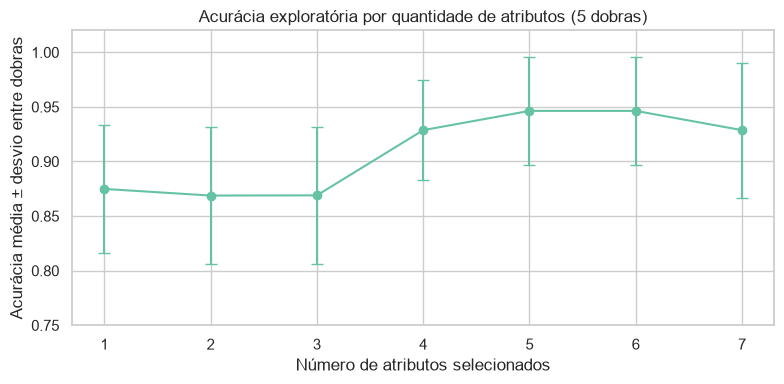

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    comparacao["k"], comparacao["acuracia_media"],
    yerr=comparacao["desvio_entre_dobras"], marker="o", capsize=4,
)
ax.set(
    title="Acurácia exploratória por quantidade de atributos (5 dobras)",
    xlabel="Número de atributos selecionados", ylabel="Acurácia média ± desvio entre dobras",
    xticks=comparacao["k"], ylim=(0.75, 1.02),
)
plt.tight_layout()
plt.show()

In [19]:
# Regra de 1 erro padrão: dentre os resultados próximos ao melhor, preferir menos atributos.
melhor = comparacao.loc[comparacao["acuracia_media"].idxmax()]
limiar = melhor["acuracia_media"] - melhor["desvio_entre_dobras"] / np.sqrt(validacao.n_splits)
k_escolhido = int(comparacao.loc[comparacao["acuracia_media"] >= limiar, "k"].min())
seletor_final = SelectKBest(score_func=f_classif, k=k_escolhido).fit(X_treino, y_treino)
atributos_selecionados = X_treino.columns[seletor_final.get_support()].tolist()
X_treino_selecionado = X_treino[atributos_selecionados].copy()

print(f"Acurácia exploratória com 7 atributos: {comparacao.loc[comparacao.k == 7, 'acuracia_media'].iloc[0]:.3f}")
print(f"Maior média: {melhor['acuracia_media']:.3f} com k={int(melhor['k'])}")
print(f"Limiar de 1 erro padrão: {limiar:.3f}")
print(f"Subconjunto recomendado ({k_escolhido}): {atributos_selecionados}")
print("Formato do treino selecionado:", X_treino_selecionado.shape)

Acurácia exploratória com 7 atributos: 0.929
Maior média: 0.946 com k=5
Limiar de 1 erro padrão: 0.924
Subconjunto recomendado (4): ['area', 'perimetro', 'largura_grao', 'comprimento_sulco']
Formato do treino selecionado: (168, 4)


**Conclusão da seleção:** a maior acurácia média exploratória foi **0,946** com cinco ou seis atributos. A regra de 1 erro padrão recomenda quatro atributos — área, perímetro, largura do grão e comprimento do sulco — com média **0,929**, igual à obtida com os sete atributos. Os escores de validação cruzada podem ser otimistas após a escolha de `k`. A estatística F individual não mede a contribuição independente de atributos correlacionados. Na próxima entrega, ajuste o pipeline no treino e avalie uma única vez no teste reservado.